# Testes e Avaliações de Agrupamento (Clusterização)

Modelos não supervisionados não possuem rótulo fixo e, por isso, a validação depende de medidas internas e externas.

Tipos avaliados:
- avaliação interna: Silhouette Score
- avaliação externa: Adjusted Rand Index (ARI)


Silhouette Score KMeans = 0.1829


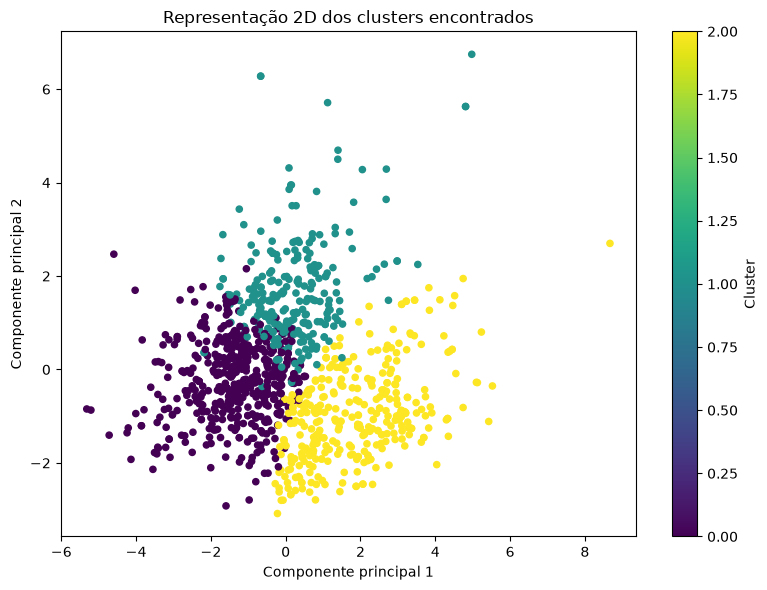

In [5]:
import pandas as pd
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

wine = pd.read_csv('../data/WineQT.csv')
X = wine[[c for c in wine.columns if c not in {'quality', 'Id'}]]
X_scaled = StandardScaler().fit_transform(X)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=20)
labels_kmeans = kmeans.fit_predict(X_scaled)
print('Silhouette Score KMeans =', round(silhouette_score(X_scaled, labels_kmeans), 4))

import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels_kmeans, cmap='viridis', s=20)
plt.title('Representação 2D dos clusters encontrados')
plt.xlabel('Componente principal 1')
plt.ylabel('Componente principal 2')
plt.colorbar(label='Cluster')
plt.tight_layout()
plt.show()


In [6]:
agg = AgglomerativeClustering(n_clusters=3)
labels_agg = agg.fit_predict(X_scaled)
print('Adjusted Rand Index (KMeans x Agglomerative) =', round(adjusted_rand_score(labels_kmeans, labels_agg), 4))


Adjusted Rand Index (KMeans x Agglomerative) = 0.4791


# Interpretação
#
# A clusterização não deve ser usada como substituta de avaliação supervisionada quando o objetivo é predição.
# Ainda assim, os testes de Silhouette e ARI ajudam a verificar se os dados apresentam estrutura natural e
# se diferentes métodos convergem para padrões semelhantes.
